# Datos: `transforms`, `Dataset` y `DataLoader`

En el módulo 1 los datos cabían en un tensor: diez entregas, doscientos puntos, dos mil casas. En este módulo pasamos a imágenes, y cada imagen trae cientos de números. Este notebook arma el camino que siguen los datos desde el disco hasta el modelo, con las tres herramientas que PyTorch tiene para eso:

- **`transforms`** prepara cada muestra en el momento de cargarla.
- **`Dataset`** sabe dónde están los datos, cuántos hay y cómo cargar uno.
- **`DataLoader`** le pide muestras al `Dataset`, las junta en lotes y se las entrega al modelo.

Usamos **MNIST**, el conjunto de dígitos escritos a mano con el que trabaja todo el módulo. Los demás notebooks del módulo parten de lo que se arma aquí.

**Contenido**

1. Preparación
2. Por qué no cargar todo de una vez
3. MNIST
4. `ToTensor`: de imagen a tensor
5. `Normalize`: centrar y escalar
6. `Compose`: encadenar pasos
7. `Dataset`: cargar solo lo que se pide
8. `DataLoader`: de muestras a lotes
9. Cuánto cuesta cargar
10. Resumen y ejercicios

## 1. Preparación

`torchvision` es la librería de PyTorch para visión por computador. Trae conjuntos de datos listos para descargar (`datasets`) y las transformaciones habituales para imágenes (`transforms`). Se instala aparte: `pip install torchvision` (Colab ya la trae).

Los datos se descargan una sola vez en `modulo-2/data`, una carpeta que comparten todos los notebooks del módulo. Desde cada notebook esa carpeta es `../data`.

In [1]:
import time

import torch
import torchvision
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("Versión de PyTorch    :", torch.__version__)
print("Versión de torchvision:", torchvision.__version__)

RAIZ = "../data"       # modulo-2/data

Versión de PyTorch    : 2.11.0+cpu
Versión de torchvision: 0.26.0+cpu


## 2. Por qué no cargar todo de una vez

Un tensor ocupa 4 bytes por número cuando es `float32`. Con eso se puede calcular cuánta memoria pide un conjunto de datos completo:

In [2]:
def tamano_legible(n_bytes):
    for unidad in ["B", "KB", "MB", "GB", "TB"]:
        if n_bytes < 1000:
            return f"{n_bytes:.0f} {unidad}"
        n_bytes /= 1000


casos = [
    ("100.000 entregas con 5 columnas", 100_000, 5),
    ("MNIST: 60.000 imágenes de 28 × 28", 60_000, 28 * 28),
    ("ImageNet: 1,28 millones de fotos de 3 × 224 × 224", 1_281_167, 3 * 224 * 224),
]
for nombre, ejemplos, valores in casos:
    print(f"{nombre:52s} {tamano_legible(ejemplos * valores * 4):>8s}")

100.000 entregas con 5 columnas                          2 MB
MNIST: 60.000 imágenes de 28 × 28                      188 MB
ImageNet: 1,28 millones de fotos de 3 × 224 × 224      771 GB


Las entregas caben sin problema. MNIST también, aunque ya ocupa lo que una aplicación grande. ImageNet, el conjunto de fotos con el que se entrenaron muchas de las redes de visión conocidas, no cabe en la memoria de ningún computador personal.

La salida es trabajar por **lotes**: cargar unas decenas de ejemplos, usarlos para un paso de entrenamiento y soltarlos. El módulo 1 usó lotes para abaratar cada paso (`02-descenso-de-gradiente/02_sgd_y_minibatches`). Aquí aparece la otra razón, la memoria. La regla es cargar solo lo que se necesita, cuando se necesita.

## 3. MNIST

MNIST tiene 70.000 imágenes de dígitos escritos a mano, del 0 al 9: 60.000 para entrenar y 10.000 de prueba. Cada imagen mide 28 × 28 píxeles, está en escala de grises y tiene el dígito centrado. Es el "hola mundo" de la visión por computador: lo bastante difícil para que ninguna regla escrita a mano funcione bien, y lo bastante pequeño para entrenar en minutos en un computador común.

`datasets.MNIST` recibe tres argumentos:

- `root`: la carpeta donde guardar los archivos.
- `train`: `True` para las 60.000 imágenes de entrenamiento, `False` para las 10.000 de prueba.
- `download=True`: si los archivos no están en `root`, los descarga (unos 12 MB comprimidos).

In [3]:
entrenamiento = datasets.MNIST(root=RAIZ, train=True, download=True)
prueba = datasets.MNIST(root=RAIZ, train=False, download=True)

print("entrenamiento:", len(entrenamiento), "imágenes")
print("prueba       :", len(prueba), "imágenes")

entrenamiento: 60000 imágenes
prueba       : 10000 imágenes


Un dataset se indexa como una lista. Sin transformaciones, cada elemento es un par (imagen, etiqueta), y la imagen es un objeto de PIL, la librería de imágenes de Python, no un tensor:

In [4]:
imagen, etiqueta = entrenamiento[0]
print(type(imagen), imagen.size, imagen.mode)
print("etiqueta:", etiqueta)

<class 'PIL.Image.Image'> (28, 28) L
etiqueta: 5


El modo `"L"` es escala de grises con 8 bits: cada píxel es un entero entre 0 (negro) y 255 (blanco). Miremos las primeras 24 imágenes:

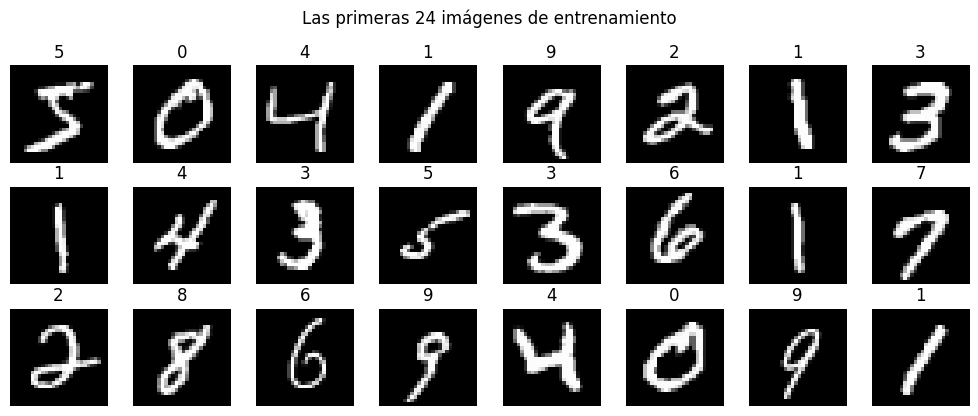

In [5]:
fig, ejes = plt.subplots(3, 8, figsize=(10, 4.2))
for i, eje in enumerate(ejes.flat):
    imagen, etiqueta = entrenamiento[i]
    eje.imshow(imagen, cmap="gray")
    eje.set_title(etiqueta)
    eje.axis("off")
plt.suptitle("Las primeras 24 imágenes de entrenamiento")
plt.tight_layout()
plt.show()

Hay trazos gruesos y finos, dígitos inclinados, unos que se cierran y otros que no. Esa variedad es lo que el modelo tiene que aprender a ignorar.

Antes de entrenar conviene revisar si las clases están balanceadas: si un dígito fuera muy escaso, un modelo podría ignorarlo y aun así tener buena exactitud. `entrenamiento.targets` guarda las 60.000 etiquetas en un tensor:

In [6]:
conteo = torch.bincount(entrenamiento.targets, minlength=10)
for digito, n in enumerate(conteo.tolist()):
    print(f"{digito}: {n:5d}  {n / len(entrenamiento):5.1%}")

0:  5923   9.9%
1:  6742  11.2%
2:  5958   9.9%
3:  6131  10.2%
4:  5842   9.7%
5:  5421   9.0%
6:  5918   9.9%
7:  6265  10.4%
8:  5851   9.8%
9:  5949   9.9%


Cada dígito está entre el 9% y el 11% de las imágenes, así que las clases están balanceadas. Eso hace que la **exactitud** (aciertos sobre total) sea una métrica razonable aquí. Como referencia, un modelo que contestara siempre "1", la clase más común, acertaría el 11%.

## 4. `ToTensor`: de imagen a tensor

Un modelo recibe tensores, no imágenes de PIL. `transforms.ToTensor()` hace tres cosas a la vez:

1. Convierte la imagen en un tensor.
2. Pasa los enteros de 0 a 255 a `float32` entre 0 y 1, dividiéndolos por 255.
3. Pone primero la dimensión de los **canales**, de modo que la forma queda `[canales, alto, ancho]`. Una imagen en escala de grises tiene un canal, así que queda `[1, 28, 28]`. Una foto en color tendría tres: rojo, verde y azul.

In [7]:
a_tensor = transforms.ToTensor()

imagen, etiqueta = entrenamiento[0]
x = a_tensor(imagen)

print("forma:", x.shape, "  tipo:", x.dtype)
print(f"mínimo {x.min():.3f}   máximo {x.max():.3f}")

forma: torch.Size([1, 28, 28])   tipo: torch.float32
mínimo 0.000   máximo 1.000


No hace nada misterioso. Los píxeles originales están en `entrenamiento.data` como enteros de 8 bits, y dividirlos por 255 da exactamente lo mismo:

In [8]:
crudo = entrenamiento.data[0]          # forma [28, 28], tipo uint8
print(crudo.shape, crudo.dtype)
print("¿Igual que ToTensor?", torch.equal(x, (crudo.float() / 255).unsqueeze(0)))

torch.Size([28, 28]) torch.uint8
¿Igual que ToTensor? True


## 5. `Normalize`: centrar y escalar

Después de `ToTensor` los píxeles están entre 0 y 1, y la mayoría valen 0: el fondo negro. En el módulo 1 vimos que el descenso de gradiente funciona mejor cuando las entradas están centradas en 0 y tienen una escala parecida (`02-descenso-de-gradiente/01_descenso_de_gradiente`, sección 8). `transforms.Normalize(media, desviación)` le resta la media a cada píxel y divide por la desviación estándar:

$$x_{\text{norm}} = \frac{x - \text{media}}{\text{desviación}}$$

Los números 0.1307 y 0.3081, que aparecen en todos los ejemplos de MNIST, son la media y la desviación de todos los píxeles del conjunto de entrenamiento. Podemos calcularlos:

In [9]:
pixeles = entrenamiento.data.float() / 255          # 60.000 × 28 × 28 píxeles, entre 0 y 1
media = pixeles.mean().item()
desviacion = pixeles.std().item()
print(f"media {media:.4f}   desviación {desviacion:.4f}")

media 0.1307   desviación 0.3081


Tres detalles:

- Se calculan **solo con el conjunto de entrenamiento** y se usan los mismos en la prueba. Es la regla del proyecto de punta a punta del módulo 1: la prueba hace el papel de datos que llegan después, y de esos datos no se conocen las estadísticas de antemano.
- Se usan **los mismos dos números para todas las imágenes**. Si cada imagen se normalizara con su propia media, una imagen de trazo grueso y otra de trazo fino terminarían en escalas distintas, y el modelo perdería información.
- `Normalize` recibe una tupla con un valor por canal: `(0.1307,)` y no `0.1307`. MNIST tiene un canal; una foto en color llevaría tres valores.

Después de normalizar, el fondo ya no vale 0:

In [10]:
normalizar = transforms.Normalize((media,), (desviacion,))
x_norm = normalizar(x)

print(f"fondo (antes 0): {x_norm.min():.3f}")
print(f"trazo (antes 1): {x_norm.max():.3f}")

fondo (antes 0): -0.424
trazo (antes 1): 2.822


El fondo queda en $(0 - 0.1307) / 0.3081 \approx -0.42$ y el trazo más blanco en $(1 - 0.1307) / 0.3081 \approx 2.82$.

En los apuntes del curso también aparece `Normalize((0.5,), (0.5,))`. Esos valores no son estadísticas de nada: llevan el rango [0, 1] a [-1, 1]. Funciona, pero los datos no quedan con media 0 y desviación 1. Lo comparamos con 1.000 imágenes:

In [11]:
muestra = pixeles[:1000]
for nombre, m, d in [("estadísticas de MNIST", media, desviacion), ("0.5 y 0.5", 0.5, 0.5)]:
    z = (muestra - m) / d
    print(f"{nombre:22s} media {z.mean():6.3f}   desviación {z.std():.3f}   rango [{z.min():.2f}, {z.max():.2f}]")

estadísticas de MNIST  media -0.008   desviación 0.990   rango [-0.42, 2.82]
0.5 y 0.5              media -0.744   desviación 0.610   rango [-1.00, 1.00]


Con 0.5 la media queda en -0.74: como casi toda la imagen es fondo negro, casi todos los píxeles terminan en -1. Para una red pequeña como las de este módulo la diferencia en el resultado es menor. Lo que conviene llevarse es el procedimiento, porque sirve para cualquier conjunto de datos: medir la media y la desviación en el entrenamiento y usarlas en todas partes.

## 6. `Compose`: encadenar pasos

`transforms.Compose` recibe una lista de transformaciones y las aplica en orden. Este es el pipeline estándar de MNIST, el que usa el resto del módulo:

In [12]:
transformacion = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

entrenamiento = datasets.MNIST(root=RAIZ, train=True, download=True, transform=transformacion)
prueba = datasets.MNIST(root=RAIZ, train=False, download=True, transform=transformacion)

x, etiqueta = entrenamiento[0]
print(type(x), x.shape, x.dtype, "  etiqueta:", etiqueta)

<class 'torch.Tensor'> torch.Size([1, 28, 28]) torch.float32   etiqueta: 5


Ahora `entrenamiento[0]` entrega directamente un tensor normalizado. La prueba usa **la misma** transformación.

El orden de la lista importa. `Normalize` trabaja sobre tensores, así que va después de `ToTensor`. Si se ponen al revés, el error no aparece al construir el `Compose` sino al pedir una muestra:

In [13]:
al_reves = transforms.Compose([transforms.Normalize((0.1307,), (0.3081,)), transforms.ToTensor()])
mal = datasets.MNIST(root=RAIZ, train=True, transform=al_reves)
print("dataset creado sin problemas")

try:
    mal[0]
except TypeError as error:
    print("TypeError:", error)

dataset creado sin problemas
TypeError: img should be Tensor Image. Got <class 'PIL.Image.Image'>


Que el error aparezca recién al pedir la muestra revela cómo funcionan: **las transformaciones se ejecutan cada vez que se pide una muestra**, no una vez al crear el dataset. Se nota con una transformación aleatoria. `RandomRotation(25)` gira la imagen en un ángulo al azar entre −25° y 25°, y lo sortea de nuevo en cada acceso:

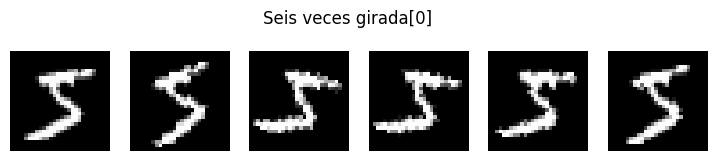

In [14]:
girada = datasets.MNIST(root=RAIZ, train=True, transform=transforms.Compose([
    transforms.RandomRotation(25),
    transforms.ToTensor(),
]))

fig, ejes = plt.subplots(1, 6, figsize=(9, 1.9))
for eje in ejes:
    x, etiqueta = girada[0]                 # siempre la misma imagen
    eje.imshow(x[0], cmap="gray")
    eje.axis("off")
plt.suptitle("Seis veces girada[0]")
plt.show()

Es la misma imagen, pedida seis veces, y sale distinta cada vez. Esto se usa para **aumentar los datos**: en cada época el modelo ve versiones algo distintas de cada imagen, y le cuesta más memorizarlas. En este módulo nos quedamos con `ToTensor` y `Normalize`.

## 7. `Dataset`: cargar solo lo que se pide

Un `Dataset` de PyTorch es cualquier objeto con dos métodos:

- `__len__()`: cuántas muestras hay. Es lo que contesta `len(dataset)`.
- `__getitem__(i)`: carga y devuelve la muestra `i`. Es lo que se ejecuta al escribir `dataset[i]`.

`datasets.MNIST` es uno de ellos. Como MNIST es pequeño, guarda todos los píxeles en memoria como enteros de 8 bits (47 MB) y deja para `__getitem__` la conversión y las transformaciones. Un dataset de fotos guarda solo la lista de archivos y lee cada uno del disco recién en `__getitem__`. En el módulo 3 se arman datasets propios de ese tipo.

Para ver cuándo se cargan las muestras, envolvemos el dataset en otro que anota cada índice que le piden:

In [15]:
class Contador(Dataset):
    """Envuelve otro Dataset y anota qué índices se le piden."""

    def __init__(self, base):
        self.base = base
        self.pedidos = []

    def __len__(self):
        return len(self.base)

    def __getitem__(self, i):
        self.pedidos.append(i)
        return self.base[i]


contado = Contador(entrenamiento)
cargador = DataLoader(contado, batch_size=64, shuffle=True)
print("muestras cargadas al crear el DataLoader:", len(contado.pedidos))

x, y = next(iter(cargador))
print("muestras cargadas después de un lote    :", len(contado.pedidos))
print("primeros índices pedidos                :", contado.pedidos[:8])

muestras cargadas al crear el DataLoader: 0
muestras cargadas después de un lote    : 64
primeros índices pedidos                : [42022, 14611, 57087, 19412, 8111, 54025, 48428, 23154]


Crear el `DataLoader` no carga nada. Pedir un lote carga exactamente 64 muestras, en un orden al azar porque usamos `shuffle=True`. Las otras 59.936 no se tocaron.

## 8. `DataLoader`: de muestras a lotes

El `DataLoader` recorre el `Dataset`, le pide muestras y las junta en lotes. Sus dos parámetros principales:

- `batch_size`: cuántas muestras por lote.
- `shuffle`: si el orden se sortea de nuevo al empezar cada época.

Usamos los valores del curso: lotes de 64 mezclados para entrenar y lotes de 1.000 sin mezclar para la prueba. La prueba admite lotes más grandes porque al evaluar no se guardan los cálculos intermedios que hacen falta para los gradientes, y son esos cálculos los que ocupan memoria (`01-modelos/01_nn_module`, sección 9).

In [16]:
cargador_entrenamiento = DataLoader(entrenamiento, batch_size=64, shuffle=True)
cargador_prueba = DataLoader(prueba, batch_size=1000, shuffle=False)

x, y = next(iter(cargador_entrenamiento))
print("un lote de imágenes :", x.shape, x.dtype)
print("un lote de etiquetas:", y.shape, y.dtype)
print()
print("lotes por época, entrenamiento:", len(cargador_entrenamiento))
print("lotes por época, prueba       :", len(cargador_prueba))

un lote de imágenes : torch.Size([64, 1, 28, 28]) torch.float32
un lote de etiquetas: torch.Size([64]) torch.int64

lotes por época, entrenamiento: 938
lotes por época, prueba       : 10


Las formas que llegan al modelo:

- Las imágenes vienen como `[64, 1, 28, 28]`: **[lote, canales, alto, ancho]**. Es el orden que usan todas las capas de imágenes de PyTorch.
- Las etiquetas vienen como `[64]`, enteros `int64`: un número de clase por imagen. Es justo lo que espera `CrossEntropyLoss` (`02-entrenamiento/01_funciones_de_perdida_en_la_practica`).

Como 60.000 / 64 = 937.5, hay 938 lotes: 937 completos y uno final con las imágenes que sobran. Con `drop_last=True` ese último lote se descarta.

In [17]:
n = len(entrenamiento)
print("lotes completos:", n // 64, "  imágenes en el último lote:", n % 64)
print("con drop_last=True:", len(DataLoader(entrenamiento, batch_size=64, drop_last=True)), "lotes")

lotes completos: 937   imágenes en el último lote: 32
con drop_last=True: 937 lotes


Para armar un lote, el `DataLoader` pide las muestras una por una y apila las imágenes con `torch.stack`, que agrega una dimensión nueva al frente. Las etiquetas, que son enteros de Python, las junta en un tensor. Hecho a mano con cuatro muestras da lo mismo:

In [18]:
muestras = [entrenamiento[i] for i in range(4)]
imagenes = torch.stack([imagen for imagen, _ in muestras])
etiquetas = torch.tensor([etiqueta for _, etiqueta in muestras])

x, y = next(iter(DataLoader(entrenamiento, batch_size=4)))
print("a mano       :", imagenes.shape, etiquetas)
print("con el loader:", x.shape, y)
print("¿Iguales?", torch.equal(imagenes, x) and torch.equal(etiquetas, y))

a mano       : torch.Size([4, 1, 28, 28]) tensor([5, 0, 4, 1])
con el loader: torch.Size([4, 1, 28, 28]) tensor([5, 0, 4, 1])
¿Iguales? True


**Mezclar en cada época.** Con `shuffle=True` el orden se sortea de nuevo cada vez que se empieza a recorrer el cargador. Las etiquetas del primer lote en tres recorridos distintos:

In [19]:
for epoca in range(3):
    _, y = next(iter(cargador_entrenamiento))
    print(f"entrenamiento, época {epoca}: {y[:12].tolist()}")

for epoca in range(2):
    _, y = next(iter(cargador_prueba))
    print(f"prueba, época {epoca}       : {y[:12].tolist()}")

entrenamiento, época 0: [7, 2, 6, 0, 0, 4, 1, 6, 5, 2, 6, 8]
entrenamiento, época 1: [9, 4, 8, 7, 5, 7, 7, 5, 8, 7, 4, 0]
entrenamiento, época 2: [2, 3, 6, 7, 3, 7, 9, 4, 1, 4, 1, 2]


prueba, época 0       : [7, 2, 1, 0, 4, 1, 4, 9, 5, 9, 0, 6]


prueba, época 1       : [7, 2, 1, 0, 4, 1, 4, 9, 5, 9, 0, 6]


¿Por qué mezclar el entrenamiento? Muchos conjuntos de datos vienen ordenados por clase. Sin mezclar, el modelo vería solo ceros durante un buen rato, después solo unos, y así; en cada tramo aprendería a contestar el dígito de turno y olvidaría los anteriores. MNIST ya viene mezclado (las primeras etiquetas son 5, 0, 4, 1, 9), así que aquí el efecto sería pequeño. En `04-clasificacion-de-imagenes/02_experimentos_con_mnist` lo ordenamos a propósito para ver qué pasa.

Al evaluar el orden da igual: la exactitud es la misma en cualquier orden. Por eso la prueba no se mezcla, y así sus lotes son siempre los mismos.

## 9. Cuánto cuesta cargar

Las transformaciones se ejecutan en cada acceso, y eso tiene un costo: en cada época, `ToTensor` y `Normalize` se vuelven a aplicar a las 60.000 imágenes. MNIST cabe en memoria, así que hay una alternativa: transformar todo una vez y guardar el resultado en un `TensorDataset`. Primero comprobamos que da lo mismo:

In [20]:
X_entrenamiento = ((entrenamiento.data.float() / 255 - 0.1307) / 0.3081).unsqueeze(1)    # [60000, 1, 28, 28]
y_entrenamiento = entrenamiento.targets
en_memoria = TensorDataset(X_entrenamiento, y_entrenamiento)

x_pipeline, _ = entrenamiento[123]
x_memoria, _ = en_memoria[123]
print("forma:", X_entrenamiento.shape)
print("¿La misma muestra?", torch.allclose(x_pipeline, x_memoria))
print("memoria ocupada:", tamano_legible(X_entrenamiento.numel() * X_entrenamiento.element_size()))

forma: torch.Size([60000, 1, 28, 28])
¿La misma muestra? True
memoria ocupada: 188 MB


Y medimos cuánto tarda cada uno en entregar 300 lotes, sin entrenar nada:

In [21]:
def recorrer(cargador, lotes=300):
    inicio = time.perf_counter()
    for i, (x, y) in enumerate(cargador):
        if i + 1 == lotes:
            break
    return time.perf_counter() - inicio


t_pipeline = recorrer(DataLoader(entrenamiento, batch_size=64, shuffle=True))
t_memoria = recorrer(DataLoader(en_memoria, batch_size=64, shuffle=True))

print(f"con transforms   : {t_pipeline:5.2f} s por 300 lotes   ->  una época, unos {t_pipeline * 938 / 300:4.1f} s")
print(f"desde la memoria : {t_memoria:5.2f} s por 300 lotes   ->  una época, unos {t_memoria * 938 / 300:4.1f} s")
print(f"\nla versión en memoria es {t_pipeline / t_memoria:.0f} veces más rápida")

con transforms   :  4.25 s por 300 lotes   ->  una época, unos 13.3 s
desde la memoria :  0.20 s por 300 lotes   ->  una época, unos  0.6 s

la versión en memoria es 21 veces más rápida


Los tiempos exactos dependen del computador, pero la diferencia es grande en cualquiera. Con transforms, cada imagen pasa en cada época por la conversión desde PIL, la división y la normalización. Precargado, ese trabajo se hizo una sola vez.

¿Entonces la regla de "cargar solo lo que se necesita" está mal? No: depende de si los datos caben.

- **Si los datos ya transformados caben en memoria**, como MNIST con sus 188 MB, precargarlos es lo más rápido.
- **Si no caben**, como ImageNet, hace falta el `Dataset` que carga a pedido. Para que no frene el entrenamiento, el `DataLoader` tiene el parámetro `num_workers`: lanza varios procesos que van preparando los lotes siguientes mientras el modelo entrena con el actual.
- **Si las transformaciones son aleatorias**, como `RandomRotation`, no se pueden precargar: la gracia es que cambien en cada época.

En el resto del módulo, el notebook principal de clasificación (`04-clasificacion-de-imagenes/01_mnist_de_punta_a_punta`) usa el pipeline completo, como en el curso. Los notebooks que comparan muchas variantes precargan los datos para que cada entrenamiento tome segundos en vez de minutos.

## 10. Resumen

- Los conjuntos de datos grandes no caben en memoria, así que se trabaja por **lotes**.
- **`ToTensor`** convierte una imagen de enteros entre 0 y 255 en un tensor `float32` entre 0 y 1, con forma `[canales, alto, ancho]`.
- **`Normalize(media, desviación)`** centra y escala cada canal. La media y la desviación se calculan en el entrenamiento y se usan iguales en todas partes. Para MNIST son 0.1307 y 0.3081.
- **`Compose`** aplica las transformaciones en orden. `Normalize` va después de `ToTensor`.
- Las transformaciones se ejecutan **cada vez** que se pide una muestra. Por eso una transformación aleatoria entrega una versión distinta en cada época.
- Un **`Dataset`** es cualquier objeto con `__len__` y `__getitem__`, y carga cada muestra recién cuando se la piden.
- Un **`DataLoader`** junta muestras en lotes de forma `[lote, canales, alto, ancho]` y etiquetas `int64` de forma `[lote]`. Tiene `len(dataset) / batch_size` lotes por época, redondeado hacia arriba.
- El entrenamiento se mezcla (`shuffle=True`) y la prueba no.
- Si los datos transformados caben en memoria, precargarlos ahorra repetir el trabajo en cada época.

## Ejercicios

1. Antes de ejecutar nada: con `batch_size=100`, ¿cuántos lotes tiene una época de entrenamiento y cuántas imágenes trae el último? ¿Y con `batch_size=128`? Compruébalo.
2. Usa el `Contador` de la sección 7 con `shuffle=False`. ¿Qué índices pide el primer lote? ¿Y el segundo?
3. Calcula la media y la desviación de los píxeles del conjunto de prueba. Salen parecidas a las del entrenamiento, pero no iguales. ¿Por qué igual se normaliza la prueba con 0.1307 y 0.3081?
4. Agrega `transforms.RandomRotation(25)` al principio del pipeline de entrenamiento y mide con `recorrer` cuánto tardan 300 lotes. ¿Se podría precargar este pipeline?
5. `datasets.FashionMNIST` tiene la misma interfaz que MNIST, con fotos de ropa en vez de dígitos. Cárgalo, mira algunas imágenes y calcula su media y su desviación.
6. En un script `.py`, mide cuánto tarda una época del pipeline con `num_workers=0`, `2` y `4`. (Se pide un script porque en Windows los procesos auxiliares del `DataLoader` a veces no arrancan desde un notebook.) ¿Por qué el beneficio deja de crecer pasado cierto número?